# Tianhao Wu：96车道真实重跑与可复核交付 · 2026-11-04

本Notebook对应实际完成的**224候选、16监督臂+4基准、557160条预测**。默认离线复核本次真实产物，无需个人project.local.json、原始ZIP或模型二进制。设置RETRAIN=True并提供解压Release和认证来源缓存，可完整重新构建、调参和训练。

**96个冻结车道中94个产生拥堵事件；30452事件，27858已知30分钟标签。** 四组为本地→历史→日历→天气，Release缺逐日流量/占有率，不能混用旧24车道flow或跨队列分数。恢复目标为持续恢复确认，仍有Proposal定义和空间匹配待确认。测试此前已经接触，本次不宣称首次盲测。

保留原始训练manifest、历史源代码和配置；发布时的可移植修复另行记录，不篡改历史Git/运行身份。

## 0. 从任意工作目录找到仓库

In [1]:
from pathlib import Path
import os,sys,json,inspect,hashlib
import numpy as np,pandas as pd
get_ipython().run_line_magic("matplotlib","inline")
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display,Code,Image
root_hint=Path(os.environ.get('TRAFFIC_REPOSITORY',Path.cwd())).resolve()
ROOT=next(p for p in [root_hint,*root_hint.parents] if (p/'pyproject.toml').exists() and (p/'src/traffic_recovery').is_dir())
sys.path[:0]=[str(ROOT/'src'),str(ROOT/'experiments/tianhao')]
from verify_release96 import verify_bundle
from run_extended_models import sha
A=ROOT/'experiments/tianhao/expanded96_20261104'
for font in ['PingFang SC','Arial Unicode MS','Noto Sans CJK SC']:
 if font in {f.name for f in fm.fontManager.ttflist}:plt.rcParams['font.family']=font;break
plt.rcParams['axes.unicode_minus']=False
print('仓库依赖已导入；公开结果可离线核验。')

Matplotlib is building the font cache; this may take a moment.


仓库依赖已导入；公开结果可离线核验。


**本段代码说明**

- **目的与输入：** 固定当前仓库和产物目录。

- **处理方法与参数：** 依赖仓库标记，不使用作者机器路径；从外部目录运行可设置TRAFFIC_REPOSITORY。

- **如何阅读结果：** 代码与数据路径均相对仓库。

- **检查与限制：** 首次核验在读取任何指标之前执行。

## 1. SHA-256、历史代码和冻结配置

In [2]:
verification=verify_bundle()
print(verification)
publication=json.loads((A/'publication_manifest.json').read_text())
original=json.loads((A/'original_training_manifest.json').read_text())
print('历史训练身份：',original['run']['git'],'；历史运行秒数：',original['runtime_seconds'])
print('Release整包SHA256：',json.loads((A/'release_metadata.json').read_text())['assets'][0]['digest'])
display(pd.read_csv(A/'sources.csv')[['file','url','retrieved_at','sha256']])

{'status': 'passed', 'prediction_rows': 557160, 'metric_rows': 600, 'arms': 20, 'arm_splits': 60, 'candidates': 224, 'sources': 94, 'release_alignment': 'not_rechecked_without_release', 'source_bytes_rechecked': False, 'probability_replay': 'historical local receipt; requires local fitted_pipelines.joblib to rerun', 'historical_git': {'commit': '36eafdabaafa5df450e1eaf40621392470203a08', 'dirty': True}, 'scientific_approval': 'pending_team_review'}
历史训练身份： {'commit': '36eafdabaafa5df450e1eaf40621392470203a08', 'dirty': True} ；历史运行秒数： 313.68869333399925
Release整包SHA256： sha256:f5be559a6ad8df69e68fbc382fb609d13fdae40aa044c9d1fe4d7e3b2253b6b8


,file,url,retrieved_at,sha256
0,holidays_2023.html,https://www.info.gov.hk/gia/general/202205/13/...,2026-10-30T13:56:34.388464+00:00,c2abcd07ff97d806b0bcbcd07bd244693bb6422e5c7832...
1,holidays_2024.html,https://www.info.gov.hk/gia/general/202305/25/...,2026-10-30T13:56:34.389147+00:00,022ade54774d7e768ce735491af9c2fa3ed855e35db6b0...
2,holidays_2025.html,https://www.info.gov.hk/gia/general/202405/03/...,2026-10-30T13:56:34.389207+00:00,7a954f31058623331519fa9c277de073b23b0a69d137da...
3,holidays_2026.html,https://www.info.gov.hk/gia/general/202505/16/...,2026-10-30T13:56:40.356303+00:00,bf30b71021f206a23b949281ee6c5a910cb2443352b117...
4,temperature_20230101.zip,https://app.data.gov.hk/v1/historical-archive/...,2026-10-30T14:01:17.446991+00:00,3235f20bcc86b52cc8f43b80bd62d846994902962c50d3...
...,...,...,...,...
89,wind_20260501.zip,https://app.data.gov.hk/v1/historical-archive/...,2026-10-30T14:02:00.081236+00:00,973800282cb8805654b24e5dd941f2dcb53d02b25f1dcc...
90,wind_20260601.zip,https://app.data.gov.hk/v1/historical-archive/...,2026-10-30T14:02:00.271959+00:00,19da7fadb960000528fdf499cb2381dedd5440fa800536...
91,wind_20260701.zip,https://app.data.gov.hk/v1/historical-archive/...,2026-10-30T14:02:00.444007+00:00,39afb72a078bda0ccea75b23b8b0c4565a76dd7a9151f3...
92,wind_20260801.zip,https://app.data.gov.hk/v1/historical-archive/...,2026-10-30T14:02:01.677024+00:00,a6278e41ca3793096824caa2ae625e87d47c5eaea81a7d...


**本段代码说明**

- **目的与输入：** 先验证预测、指标、来源及所有配置与代码字节。

- **处理方法与参数：** 同时检查原始训练源码、锁文件和发布源码清单；历史dirty状态如实保留。

- **如何阅读结果：** status通过指公开产物/指标/选择一致，来源共94份。

- **检查与限制：** 无模型二进制时不假称重新拟合或概率重放；原始本地重放记录单独保留。

## 2. 数据导入、标签与时间划分

,known,positive,unknown,negative,events
split,,,,,
train,13002,3428,1288,9574,14290
validation,7848,2191,709,5657,8557
test,7008,1607,597,5401,7605


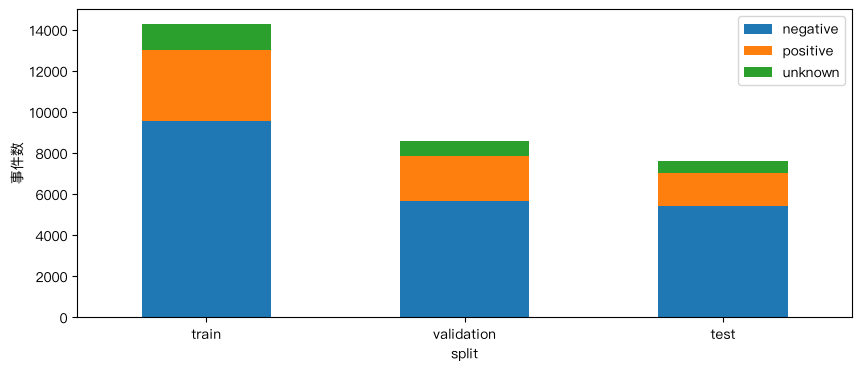

训练2023–2024；验证2025；测试2026年1–9月；2023年1月拟合参考速度。


In [3]:
pred=pd.read_parquet(A/'predictions.parquet')
base=pred.loc[pred.model.eq('majority_class')]
cohort=base.groupby('split').agg(known=('event_id','size'),positive=('y_true','sum'),unknown=('n_censored_in_split','first')).reindex(['train','validation','test'])
cohort['negative']=cohort.known-cohort.positive;cohort['events']=cohort.known+cohort.unknown
display(cohort)
assert cohort.events.sum()==30452 and cohort.known.sum()==27858 and cohort.unknown.sum()==2594
cohort[['negative','positive','unknown']].plot.bar(stacked=True,figsize=(10,4),rot=0);plt.ylabel('事件数');plt.show()
print('训练2023–2024；验证2025；测试2026年1–9月；2023年1月拟合参考速度。')

**本段代码说明**

- **目的与输入：** 读取557160条真实预测，并从单一基准臂恢复评估分母。

- **处理方法与参数：** 未知标签数取已保存审计计数，不从仅含已知标签的预测表推断。

- **如何阅读结果：** 正/负/未知分开，事件数与观测行数不同。

- **检查与限制：** 有完整Release时CLI可额外逐事件核对真值和预测时间。

## 3. 特征构建：展示与历史运行对应的源码

In [4]:
for name in ['experiments/tianhao/prepare_local.py','experiments/tianhao/prepare_external.py','src/traffic_recovery/external/calendar.py']:
 print('历史运行源码：',name)
 display(Code((A/'training_code'/name).read_text(encoding='utf-8'),language='python'))
contract=json.loads((A/'configs/contract.json').read_text())
display(pd.DataFrame([{'特征组':g,'字段数':len(cols),'实际字段':', '.join(cols)} for g,cols in contract['feature_groups'].items()]))
print('发布CLI支持显式输入、两种Release目录布局和Windows普通账户；不依赖符号链接。')

历史运行源码： experiments/tianhao/prepare_local.py


"""Past-only speed-window and flow/occupancy features; no label alteration."""
from __future__ import annotations
from pathlib import Path
import argparse, hashlib, io, json, zipfile
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from paths import ROOT, BASE, DATA
PREP = BASE / 'prepared'
KEY = ['detector_id', 'direction', 'lane_id']

def speed_features(*, data_dir: Path = DATA, output_dir: Path = PREP) -> None:
    """Rebuild each lane across arbitrary Parquet row groups, using past bins only."""
    output_dir.mkdir(parents=True, exist_ok=True)
    events = pd.read_parquet(data_dir / 'processed/derived/events.parquet').sort_values('prediction_time').reset_index(drop=True)
    rows = []
    columns = KEY + ['timestamp', 'available_at', 'speed_kmh', 'usable', 'last_source_available_at']
    for key, lane_events in events.groupby(KEY, sort=False):
        bins = pq.read_table(data_dir / 'processed/derived/cohort_bins.parquet', columns=columns,
                             filters=[(column, '=', value) for column, value in zip(KEY, key)]).to_pandas()
        bins = bins.sort_values('timestamp').set_index('timestamp')
        if not bins.index.is_unique:
            raise ValueError(f'Duplicate lane bin timestamps: {key}')
        for event in lane_events.itertuples():
            end = event.onset_confirmed_at
            window = bins.reindex(pd.date_range(end-pd.Timedelta(minutes=15), end, freq='5min'))
            valid = window.usable.astype('boolean').fillna(False).astype(bool) & window.speed_kmh.notna() & window.available_at.le(event.prediction_time) & window.last_source_available_at.le(event.prediction_time)
            ratio = window.speed_kmh.where(valid) / event.baseline_kmh
            complete = bool(valid.all())
            rows.append(dict(event_id=event.event_id, prediction_time=event.prediction_time,
                speed_change_15m_ratio=float(ratio.iloc[-1]-ratio.iloc[0]) if complete else np.nan,
                speed_mean_15m_ratio=float(ratio.mean()) if complete else np.nan,
                speed_slope_15m_ratio_per_min=float(np.polyfit(np.arange(4)*5, ratio, 1)[0]) if complete else np.nan,
                speed_trend_observed_bins=int(valid.sum()), speed_trend_window_end=end,
                speed_trend_max_available_at=window.loc[valid, 'available_at'].max()))
        print(f'Speed lane {key}: {len(lane_events)} events', flush=True)
    features = pd.DataFrame(rows)
    if not features.event_id.is_unique or set(features.event_id) != set(events.event_id):
        raise ValueError('Speed features do not cover the exact event cohort')
    features.to_parquet(output_dir / 'speed_history_features.parquet', index=False)

def flow_features(*, data_dir: Path = DATA, source_cache: Path | None = None, output_dir: Path = PREP) -> None:
    """Rebuild observed 30s flow/occupancy summaries, including midnight windows."""
    output_dir.mkdir(parents=True, exist_ok=True)
    events = pd.read_parquet(data_dir / 'processed/derived/events.parquet')
    events['feature_date'] = events.onset_confirmed_at.dt.strftime('%Y%m%d')
    path = (source_cache if source_cache is not None else BASE / 'sources') / 'traffic_prepared.zip'
    rows = []
    manifest = json.loads((data_dir / 'SHARED_DATA_MANIFEST.json').read_text(encoding='utf-8'))['files']
    with zipfile.ZipFile(path) as z:
        for j, (date, day_events) in enumerate(events.groupby('feature_date'), 1):
            member = f'processed/derived/cleaned-{date}.parquet'
            payload = z.read(member)
            assert hashlib.sha256(payload).hexdigest() == manifest[member]['sha256']
            daily = pd.read_parquet(io.BytesIO(payload))
            crosses_midnight = (day_events.onset_confirmed_at - pd.Timedelta(minutes=5)).dt.date.ne(day_events.onset_confirmed_at.dt.date).any()
            if crosses_midnight:
                previous = (pd.Timestamp(date) - pd.Timedelta(days=1)).strftime('%Y%m%d')
                prior_member = f'processed/d

历史运行源码： experiments/tianhao/prepare_external.py


"""Official gazetted holiday editions and archive-time-safe HKO station joins."""
from __future__ import annotations
from pathlib import Path
from datetime import datetime
import argparse, csv, hashlib, io, json, re, sys, zipfile
from urllib.parse import urlencode
import numpy as np
import pandas as pd
from html.parser import HTMLParser
from paths import ROOT, BASE, DATA
SOURCES = BASE / 'sources'
PREP = BASE / 'prepared'
sys.path.insert(0, str(ROOT / 'src'))
from traffic_recovery.external.calendar import calendar_features

class _HolidayHTML(HTMLParser):
    """Read table cells and page evidence using only the Python standard library."""
    def __init__(self) -> None:
        super().__init__(); self.rows = []; self.text = []; self.row = None; self.cell = None
    def handle_starttag(self, tag: str, attrs: list) -> None:
        if tag == 'tr': self.row = []
        if tag in ('td', 'th') and self.row is not None: self.cell = []
    def handle_data(self, data: str) -> None:
        self.text.append(data.strip())
        if self.cell is not None: self.cell.append(data)
    def handle_endtag(self, tag: str) -> None:
        if tag in ('td', 'th') and self.cell is not None:
            self.row.append(' '.join(''.join(self.cell).split())); self.cell = None
        if tag == 'tr' and self.row is not None:
            self.rows.append(self.row); self.row = None


def events(data_dir: Path = DATA) -> pd.DataFrame:
    return pd.read_parquet(data_dir / 'processed/derived/events.parquet')

def holidays(*, data_dir: Path = DATA, source_cache: Path = SOURCES, output_dir: Path = PREP) -> None:
    """Parse published annual editions; derive event-time calendar features."""
    output_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    editions = []
    for year in range(2023, 2027):
        path = source_cache / f'holidays_{year}.html'
        page = _HolidayHTML(); page.feed(path.read_text(encoding='utf-8-sig'))
        text = ' '.join(page.text)
        assert f'General holidays for {year}' in text
        dates = {2023: '2022-05-13', 2024: '2023-05-25', 2025: '2024-05-03', 2026: '2025-05-16'}
        published = pd.Timestamp(dates[year] + ' 11:00', tz='Asia/Hong_Kong')
        assert 'Issued at HKT 11:00' in text
        assert datetime.strptime(dates[year], '%Y-%m-%d').strftime('%B %d, %Y').replace(' 0', ' ') in text
        meta = json.loads(path.with_suffix('.html.meta.json').read_text(encoding='utf-8'))
        common = {'available_at': published, 'source_url': meta['requested_url'], 'source_retrieved_at': pd.Timestamp(meta['retrieved_at']), 'source_sha256': meta['sha256']}
        explicit = []
        for cells in page.rows:
            if len(cells) != 3 or cells[0] == 'Every Sunday':
                continue
            if not re.match('^[A-Za-z]+ \\d{1,2}$', cells[1]):
                continue
            local = datetime.strptime(f'{year} {cells[1]}', '%Y %B %d').date()
            assert local.strftime('%A') == cells[2]
            explicit.append(local)
            rows.append({'holiday_id': f'gazette-{year}-{local.isoformat()}', 'local_date': str(local), 'holiday_name': cells[0], **common})
        assert len(explicit) == 17, f'Expected 17 named general holidays for {year}'
        assert 'Every Sunday' in text
        for date in pd.date_range(f'{year}-01-01', f'{year}-12-31', freq='W-SUN'):
            if date.date() not in explicit:
                rows.append({'holiday_id': f'gazette-{year}-{date.date()}', 'local_date': str(date.date()), 'holiday_name': 'Every Sunday', **common})
        editions.append({'year': year, 'published_at': published.isoformat(), 'named_holidays': len(explicit), **{k: str(v) for k, v in common.items()}})
    table = pd.DataFrame(rows)
    assert table.local_date.is_unique
    table.to_parquet(output_dir / 'official_holiday_editions.parquet', index=False)
    context = calendar_features(events(data_dir)[['event_id', 'prediction_time']], table)
    assert context.is_public_holiday.notna(

历史运行源码： src/traffic_recovery/external/calendar.py


"""Prediction-time calendar features backed by a versioned holiday table."""
from __future__ import annotations

import math

import pandas as pd

from ._validation import (
    hkt, require_aware, require_columns, require_provenance, require_string_ids,
    timestamp_series, validate_events,
)


def calendar_features(events: pd.DataFrame, holidays: pd.DataFrame) -> pd.DataFrame:
    """Build clock and official-holiday features for each event.

    ``holidays`` must preserve the official publication availability of each
    holiday row. A holiday contributes only when its ``available_at`` is no later
    than the event prediction time. ``local_date`` is interpreted as a Hong Kong
    civil date, never as a UTC timestamp. Staging must supply complete annual
    editions. A known edition for another year cannot establish a negative;
    adjacent-day indicators require the edition for that day's year separately.
    """
    validate_events(events)
    require_columns(
        holidays,
        ["holiday_id", "local_date", "holiday_name", "available_at"],
        "holidays",
    )
    require_provenance(holidays, "holidays")
    if len(holidays):
        require_aware(holidays, ["available_at"], "holidays")
        require_string_ids(holidays, ["holiday_id"], "holidays")
        dates = pd.to_datetime(holidays.local_date, errors="raise")
        if isinstance(dates.dtype, pd.DatetimeTZDtype):
            raise ValueError("holidays.local_date must be a civil date without a timezone")
        holiday_dates = dates.dt.date
    else:
        holiday_dates = pd.Series([], dtype="object", index=holidays.index)

    rows: list[dict[str, object]] = []
    for event in events.itertuples(index=False):
        when = event.prediction_time.tz_convert("Asia/Hong_Kong")
        local_date = when.date()
        known = holidays.loc[holidays.available_at.le(when)].copy()
        known_dates = holiday_dates.loc[known.index]
        same = known_dates.eq(local_date)
        before = known_dates.eq(local_date + pd.Timedelta(days=1))
        after = known_dates.eq(local_date - pd.Timedelta(days=1))
        covered_years = {date.year for date in known_dates}
        source_observed = local_date.year in covered_years
        before_observed = (local_date + pd.Timedelta(days=1)).year in covered_years
        after_observed = (local_date - pd.Timedelta(days=1)).year in covered_years
        # Include only editions relevant to today's and adjacent-day features.
        relevant_years = {
            local_date.year, (local_date + pd.Timedelta(days=1)).year,
            (local_date - pd.Timedelta(days=1)).year,
        }
        relevant = known.loc[known_dates.map(lambda date: date.year in relevant_years)]
        angle_hour = 2 * math.pi * (when.hour * 60 + when.minute) / (24 * 60)
        angle_dow = 2 * math.pi * when.dayofweek / 7
        rows.append({
            "event_id": event.event_id,
            "prediction_time": when,
            "hour_sin": math.sin(angle_hour),
            "hour_cos": math.cos(angle_hour),
            "dow_sin": math.sin(angle_dow),
            "dow_cos": math.cos(angle_dow),
            "is_weekend": when.dayofweek >= 5,
            "is_public_holiday": bool(same.any()) if source_observed else pd.NA,
            "is_day_before_holiday": bool(before.any()) if before_observed else pd.NA,
            "is_day_after_holiday": bool(after.any()) if after_observed else pd.NA,
            "holiday_count": int(same.sum()) if source_observed else pd.NA,
            "calendar_source_observed": source_observed,
            "calendar_max_source_available_at": (
                relevant.available_at.max() if len(relevant) else pd.NaT
            ),
        })
    result = pd.DataFrame(rows)
    if len(result):
        result["prediction_time"] = hkt(result.prediction_time)
        result["calendar_max_source_available_at"] = timestamp_series(
            result.calendar_max_source_available_at.tolist(), result.index
        )
    return

,特征组,字段数,实际字段
0,local,5,"speed_kmh, speed_ratio, baseline_kmh, valid_sl..."
1,history,4,"speed_change_15m_ratio, speed_mean_15m_ratio, ..."
2,calendar,8,"hour_sin, hour_cos, dow_sin, dow_cos, is_weeke..."
3,weather,6,"temperature_c, wind_speed_kmh, temperature_age..."


发布CLI支持显式输入、两种Release目录布局和Windows普通账户；不依赖符号链接。


**本段代码说明**

- **目的与输入：** 说明历史速度、时钟、假期和天气的实际计算。

- **处理方法与参数：** 历史窗口四时点，年度事前发布版本，天气按捕获时间向后匹配并限龄60分钟。

- **如何阅读结果：** 冻结源码由原始运行SHA约束；不是不加区分地显示后来改过的函数。

- **检查与限制：** 可移植修复未修改特征公式。缺流量/占有率数值，flow_slots不是流量值。

### 3.1 新队列覆盖与真实事件示例

,scope,split,family,feature,n_events,observed,missing,missing_rate,coverage_rate
44,all_events,all,calendar,calendar_all_fields,30452,30452,0,0.000000,1.000000
45,all_events,all,weather,temperature_c,30452,30434,18,0.000591,0.999409
46,all_events,all,weather,wind_speed_kmh,30452,30336,116,0.003809,0.996191
47,all_events,all,weather,weather_both_values,30452,30331,121,0.003973,0.996027
92,known_label_30m,all,calendar,calendar_all_fields,27858,27858,0,0.000000,1.000000
93,known_label_30m,all,weather,temperature_c,27858,27840,18,0.000646,0.999354
94,known_label_30m,all,weather,wind_speed_kmh,27858,27751,107,0.003841,0.996159
95,known_label_30m,all,weather,weather_both_values,27858,27746,112,0.004020,0.995980


,event_id,prediction_time,speed_ratio,speed_change_15m_ratio,speed_mean_15m_ratio,speed_slope_15m_ratio_per_min
0,cd9bedfc70bd64b05dfd,2023-02-01 09:40:00+08:00,0.228916,-0.602410,0.465361,-0.044699
1,757b73b31d9a27efedac,2023-02-01 17:00:00+08:00,0.439759,-0.409639,0.578313,-0.029398
2,67528e60d333e667766d,2023-02-01 18:15:00+08:00,0.162651,-0.692771,0.504518,-0.053133
3,92f57abac41c774dcec3,2023-02-06 18:45:00+08:00,0.210843,-0.548193,0.501506,-0.043494
4,da243fa9e32883ce3be8,2023-02-07 09:10:00+08:00,0.337349,-0.524096,0.549699,-0.040602


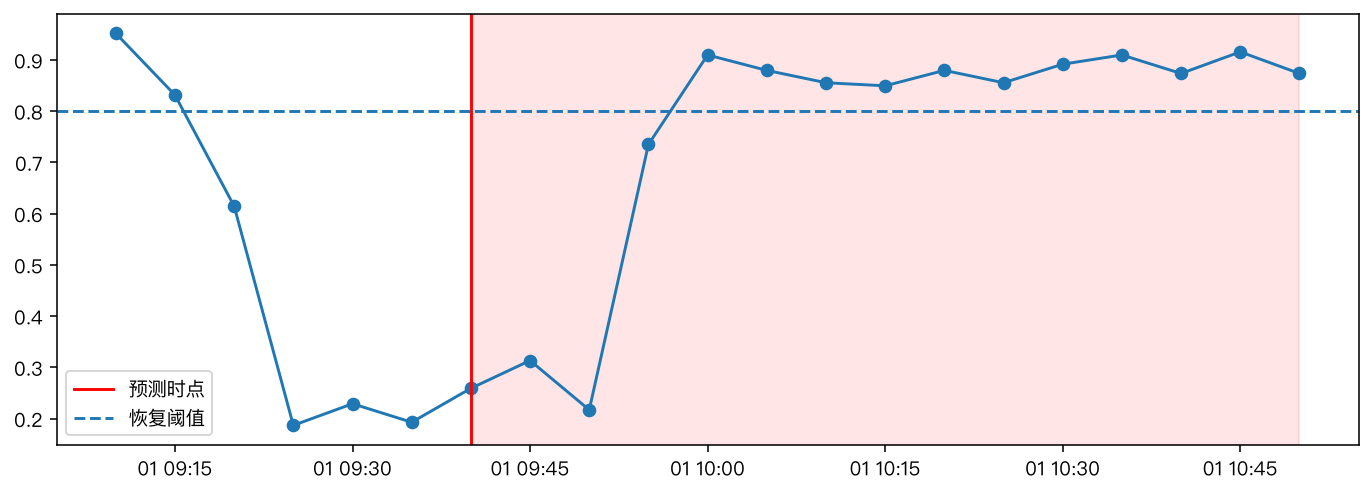

示例曲线是本轮从Release重算并逐值校验后的冻结图；红线后只解释结果。


In [5]:
coverage=pd.read_csv(A/'coverage.csv')
display(coverage.loc[coverage.split.eq('all')&coverage.feature.isin(['calendar_all_fields','temperature_c','wind_speed_kmh','weather_both_values'])])
example=pd.read_csv(A/'feature_examples.csv')
display(example[['event_id','prediction_time','speed_ratio','speed_change_15m_ratio','speed_mean_15m_ratio','speed_slope_15m_ratio_per_min']])
display(Image(filename=str(A/'figures/03_real_event.png')))
print('示例曲线是本轮从Release重算并逐值校验后的冻结图；红线后只解释结果。')

**本段代码说明**

- **目的与输入：** 展示插补前缺失、真实字段和本轮事件曲线。

- **处理方法与参数：** 覆盖分别采用全事件和已知标签分母；图与示例文件都有SHA。

- **如何阅读结果：** 预测前还须满足来源可用；图中未来部分不能入模。

- **检查与限制：** King’s Park是区域代理，不能外推最近站或全港覆盖。

## 4. 模型配置与完整训练入口

In [6]:
for name in ['supervised_rules.json','extended_rules.json']:
 print('实际训练的冻结配置：',name);display(json.loads((A/'configs'/name).read_text()))
from traffic_recovery.models.extended_classifiers import make_extended_pipeline
display(Code(inspect.getsource(make_extended_pipeline),language='python'))
# 默认复核本轮已真实完成的训练结果。重训需显式提供以下本地路径。
RETRAIN=False
RELEASE_DIR=None
SOURCE_CACHE=None
M=A
if RETRAIN:
 if RELEASE_DIR is None or SOURCE_CACHE is None:raise ValueError('Set RELEASE_DIR and SOURCE_CACHE before retraining')
 from datetime import datetime,timezone
 from run_release96 import prepare,train
 from verify_workflow import verify_run
 output=ROOT/'data/local/tianhao96-reproduction'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
 prepare(Path(RELEASE_DIR),Path(SOURCE_CACHE),output/'prepared')
 train(output/'prepared',Path(RELEASE_DIR),output/'models')
 M=output/'models'
 verify_run(M,output/'prepared/event_features.parquet',Path(RELEASE_DIR)/'processed/events.parquet')
 pred=pd.read_parquet(M/'predictions.parquet')
tuning=pd.read_csv(M/'tuning.csv');parameters=pd.read_csv(M/'selected_parameters.csv');selected=pd.read_csv(M/'validation_selected.csv')
assert len(tuning)==224 and len(parameters)==16
display(parameters[['model','feature_set','parameters','validation_log_loss']])
display(pd.DataFrame(json.loads((M/'model_summaries.json').read_text())))

实际训练的冻结配置： supervised_rules.json


{'version': 'supervised-models-v1',
 'scientific_approval': 'pending_real_cohort_and_team_review',
 'seed': 42,
 'selection_metric': 'validation_log_loss',
 'decision_threshold': 0.5,
 'refit_after_selection': False,
 'default_feature_groups': ['local'],
 'logistic_regression': {'solver': 'liblinear',
  'max_iter': 2000,
  'C': [0.1, 1.0, 10.0],
  'class_weight': [None, 'balanced']},
 'decision_tree': {'criterion': 'gini',
  'max_depth': [2, 4, 6, None],
  'min_samples_leaf': [1, 5, 10],
  'class_weight': [None, 'balanced']},
 'random_forest': {'n_estimators': [100, 300],
  'max_depth': [4, 8, None],
  'min_samples_leaf': [1, 5],
  'class_weight': [None, 'balanced']},
 'hist_gradient_boosting': {'max_depth': [3, None],
  'max_leaf_nodes': [15, 31],
  'learning_rate': [0.05, 0.1],
  'l2_regularization': [0.0, 1.0]}}

实际训练的冻结配置： extended_rules.json


{'version': 'tianhao-l1-svm-30m-v1',
 'scientific_approval': 'pending_team_review_exploratory_extension',
 'seed': 42,
 'selection_metric': 'validation_log_loss',
 'decision_threshold': 0.5,
 'refit_after_selection': False,
 'calibration_start': '2024-07-01T00:00:00+08:00',
 'minimum_purge_minutes': 60,
 'logistic_l1': {'C': [0.01, 0.1, 1.0, 10.0],
  'class_weight': [None, 'balanced'],
  'max_iter': 2000},
 'svm_rbf': {'C': [0.1, 1.0, 10.0],
  'gamma': ['scale', 0.01, 0.1],
  'class_weight': [None, 'balanced'],
  'cache_size_mb': 256}}

def make_extended_pipeline(kind: str, features: tuple[str, ...], params: dict[str, object], rules: ExtendedRules) -> Pipeline:
    """Create an unfitted numeric Pipeline; fit/calibration policy lives in train_extended."""
    if kind not in {"logistic_l1", "svm_rbf"}:
        raise ValueError(f"Unknown extended model: {kind}")
    if kind == "logistic_l1":
        # 1.8+ uses l1_ratio; older supported sklearn versions still use penalty.
        regularization = {"l1_ratio": 1.0} if inspect.signature(LogisticRegression).parameters[
            "penalty"].default == "deprecated" else {"penalty": "l1"}
        classifier = LogisticRegression(**params, **regularization, solver="liblinear",
                                         max_iter=int(rules.l1["max_iter"]), random_state=rules.seed)
    else:
        # Default SVC has no internal probability CV (including sklearn 1.9).
        classifier = SVC(**params, kernel="rbf", cache_size=float(rules.svm["cache_size_mb"]),
                         random_state=rules.seed)
    preprocess = ColumnTransformer([("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ]), list(features))], remainder="drop")
    return Pipeline([("preprocess", preprocess), ("classifier", classifier)])

,model,feature_set,parameters,validation_log_loss
0,logistic_regression,local,"{""C"": 10.0, ""class_weight"": null}",0.594382
1,decision_tree,local,"{""class_weight"": null, ""max_depth"": 6, ""min_sa...",0.539193
2,logistic_l1,local,"{""C"": 0.01, ""class_weight"": null}",0.593401
3,svm_rbf,local,"{""C"": 10.0, ""class_weight"": ""balanced"", ""gamma...",0.554009
4,logistic_regression,local+history,"{""C"": 10.0, ""class_weight"": null}",0.564735
5,decision_tree,local+history,"{""class_weight"": null, ""max_depth"": 4, ""min_sa...",0.543644
6,logistic_l1,local+history,"{""C"": 1.0, ""class_weight"": null}",0.564701
7,svm_rbf,local+history,"{""C"": 10.0, ""class_weight"": ""balanced"", ""gamma...",0.539458
8,logistic_regression,local+history+calendar,"{""C"": 10.0, ""class_weight"": null}",0.558198
9,decision_tree,local+history+calendar,"{""class_weight"": null, ""max_depth"": 4, ""min_sa...",0.533162


,model,feature_set,horizon_min,parameters,validation_log_loss,train_rows,validation_rows,test_rows,refit_after_selection,tree_depth,tree_leaves,tree_text,base_fit_n,calibration_n,calibration_method,calibration_start,support_vectors
0,logistic_regression,local,30,"{'C': 10.0, 'class_weight': None}",0.594382,13002,7848,7008,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,decision_tree,local,30,"{'max_depth': 6, 'min_samples_leaf': 10, 'clas...",0.539193,13002,7848,7008,False,6.0,55.0,|--- numeric__baseline_kmh <= 60.00\n| |--- ...,NaN,NaN,NaN,NaN,NaN
2,logistic_l1,local,30,"{'C': 0.01, 'class_weight': None}",0.593401,13002,7848,7008,False,NaN,NaN,NaN,13002.0,0.0,None,None,NaN
3,svm_rbf,local,30,"{'C': 10.0, 'gamma': 0.1, 'class_weight': 'bal...",0.554009,13002,7848,7008,False,NaN,NaN,NaN,8947.0,4055.0,sigmoid,2024-07-01T00:00:00+08:00,6478.0
4,logistic_regression,local+history,30,"{'C': 10.0, 'class_weight': None}",0.564735,13002,7848,7008,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,decision_tree,local+history,30,"{'max_depth': 4, 'min_samples_leaf': 10, 'clas...",0.543644,13002,7848,7008,False,4.0,16.0,|--- numeric__speed_slope_15m_ratio_per_min <=...,NaN,NaN,NaN,NaN,NaN
6,logistic_l1,local+history,30,"{'C': 1.0, 'class_weight': None}",0.564701,13002,7848,7008,False,NaN,NaN,NaN,13002.0,0.0,None,None,NaN
7,svm_rbf,local+history,30,"{'C': 10.0, 'gamma': 0.1, 'class_weight': 'bal...",0.539458,13002,7848,7008,False,NaN,NaN,NaN,8947.0,4055.0,sigmoid,2024-07-01T00:00:00+08:00,5901.0
8,logistic_regression,local+history+calendar,30,"{'C': 10.0, 'class_weight': None}",0.558198,13002,7848,7008,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,decision_tree,local+history+calendar,30,"{'max_depth': 4, 'min_samples_leaf': 10, 'clas...",0.533162,13002,7848,7008,False,4.0,16.0,|--- numeric__hour_cos <= 0.21\n| |--- numer...,NaN,NaN,NaN,NaN,NaN


**本段代码说明**

- **目的与输入：** 展示实际网格与选中参数，并提供原始数据完整重训入口。

- **处理方法与参数：** L2每组6、树24、L1为8、SVM18；验证log loss最小，阈值0.5，seed42。

- **如何阅读结果：** SVM前段训练拟合、后段训练校准，样本数区别在summary明确列出。

- **检查与限制：** 默认没有重新训练；224候选确实在本轮历史运行中训练过。校准时完整基础Pipeline冻结，测试不选参。

## 5. 指标、ROC/PR与混淆矩阵

,model,feature_set,n,macro_f1,balanced_accuracy,roc_auc,pr_auc,log_loss
0,decision_tree,local+history+calendar+weather,7008,0.634177,0.619244,0.773489,0.457002,0.467497
1,logistic_l1,local+history+calendar,7008,0.592095,0.583476,0.691183,0.417552,0.509373
2,logistic_regression,local+history+calendar,7008,0.593949,0.584939,0.691142,0.417671,0.509373
3,svm_rbf,local+history+calendar,7008,0.591466,0.582980,0.745075,0.437983,0.476607


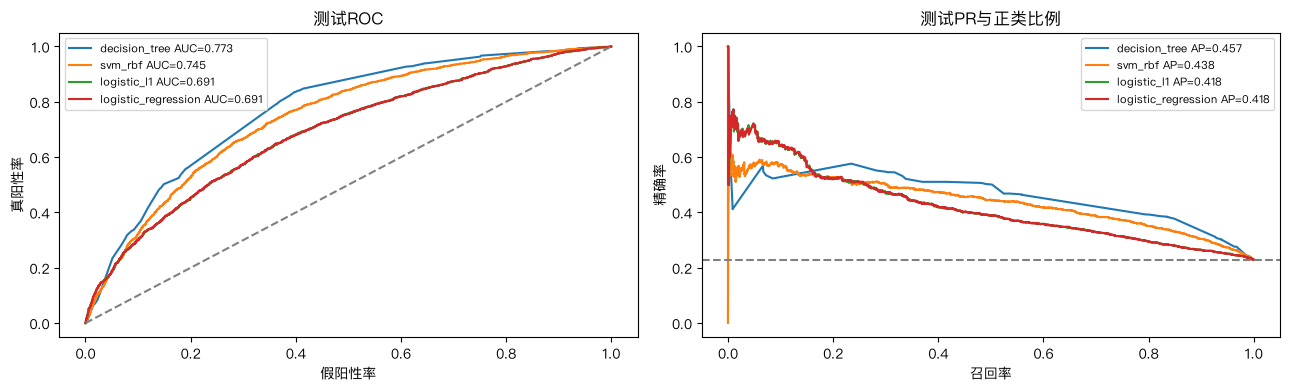

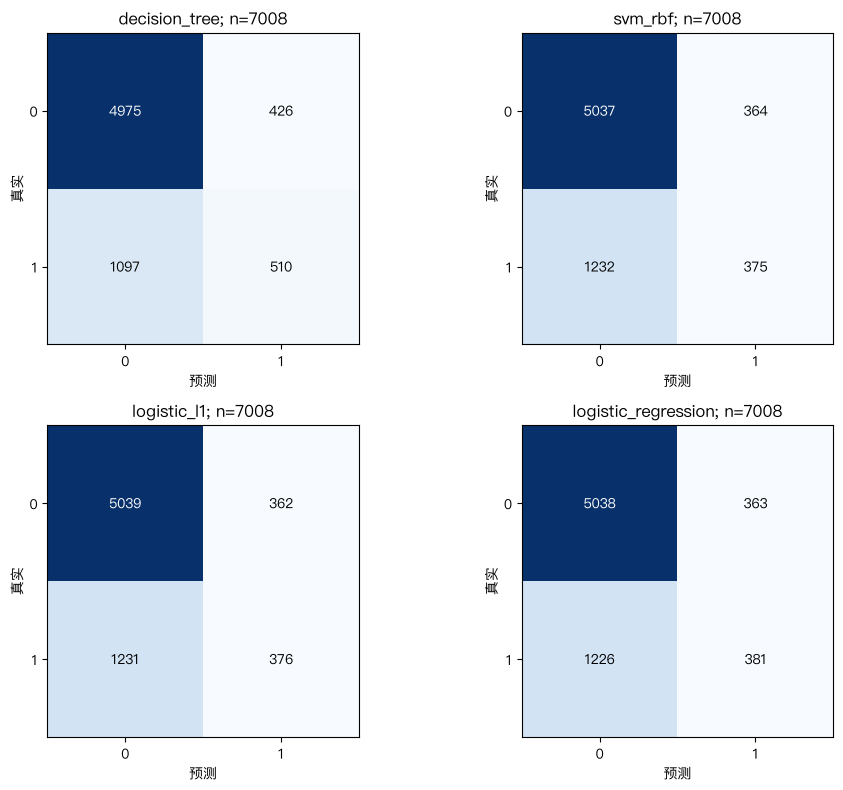

In [7]:
from sklearn.metrics import confusion_matrix,roc_curve,precision_recall_curve,roc_auc_score,average_precision_score
summary=pd.read_csv(M/'metrics_summary.csv');confusions=pd.read_csv(M/'confusion_matrices.csv')
chosen=summary.loc[summary.split.eq('test')].merge(selected[['model','feature_set']],on=['model','feature_set'],validate='one_to_one')
display(chosen[['model','feature_set','n','macro_f1','balanced_accuracy','roc_auc','pr_auc','log_loss']])
fig,axes=plt.subplots(1,2,figsize=(13,4))
for row in selected.itertuples():
 q=pred.loc[pred.model.eq(row.model)&pred.feature_set.eq(row.feature_set)&pred.split.eq('test')]
 fpr,tpr,_=roc_curve(q.y_true,q.y_score);precision,recall,_=precision_recall_curve(q.y_true,q.y_score)
 axes[0].plot(fpr,tpr,label=f'{row.model} AUC={roc_auc_score(q.y_true,q.y_score):.3f}')
 axes[1].plot(recall,precision,label=f'{row.model} AP={average_precision_score(q.y_true,q.y_score):.3f}')
axes[0].plot([0,1],[0,1],'--',color='gray');axes[0].set(xlabel='假阳性率',ylabel='真阳性率',title='测试ROC')
axes[1].axhline(q.y_true.mean(),ls='--',color='gray');axes[1].set(xlabel='召回率',ylabel='精确率',title='测试PR与正类比例')
for ax in axes:ax.legend(fontsize=8)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,2,figsize=(10,8))
for ax,row in zip(axes.flat,selected.itertuples()):
 q=pred.loc[pred.model.eq(row.model)&pred.feature_set.eq(row.feature_set)&pred.split.eq('test')]
 cm=confusion_matrix(q.y_true,q.y_pred,labels=[0,1]);ax.imshow(cm,cmap='Blues')
 for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',color='white' if v>cm.max()*.6 else 'black')
 ax.set(title=f'{row.model}; n={len(q)}',xlabel='预测',ylabel='真实',xticks=[0,1],yticks=[0,1])
plt.tight_layout();plt.show()

**本段代码说明**

- **目的与输入：** 从公开真实预测重新计算图表。

- **处理方法与参数：** 每模型采用验证选中组，矩阵固定0未恢复、1恢复。

- **如何阅读结果：** 看Macro-F1、平均召回、AUC、AP和7008个测试事件的错误分布。

- **检查与限制：** 22.9%的正类比例与旧24车道不同，不能直接比较AP高低。

### 5.1 四组增益与过拟合

,model,feature_set,reference,metric,raw_delta,improvement
0,decision_tree,local+history,local,macro_f1,-0.047393,-0.047393
1,decision_tree,local+history,local,balanced_accuracy,-0.040079,-0.040079
2,decision_tree,local+history,local,log_loss,-0.010385,0.010385
3,decision_tree,local+history,local,roc_auc,-0.030229,-0.030229
4,decision_tree,local+history,local,pr_auc,-0.049111,-0.049111
5,decision_tree,local+history+calendar,local+history,macro_f1,-0.070800,-0.070800
6,decision_tree,local+history+calendar,local+history,balanced_accuracy,-0.044451,-0.044451
7,decision_tree,local+history+calendar,local+history,log_loss,-0.012395,0.012395
8,decision_tree,local+history+calendar,local+history,roc_auc,0.025715,0.025715
9,decision_tree,local+history+calendar,local+history,pr_auc,0.020582,0.020582


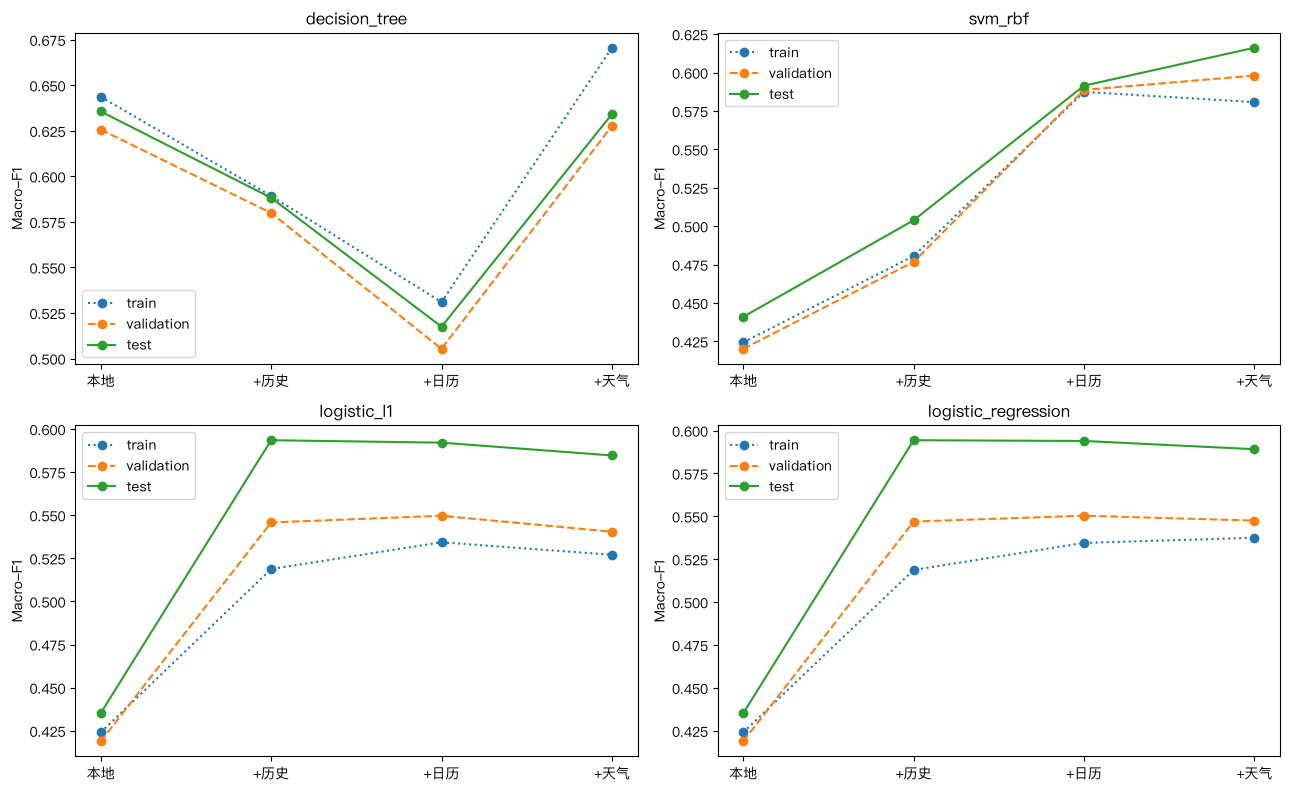

In [8]:
display(pd.read_csv(M/'feature_group_comparisons.csv'))
groups=['+'.join(list(contract['feature_groups'])[:i]) for i in range(1,5)]
fig,axes=plt.subplots(2,2,figsize=(13,8))
for ax,model in zip(axes.flat,selected.model):
 for split,style in [('train',':'),('validation','--'),('test','-')]:
  values=summary.loc[summary.model.eq(model)&summary.split.eq(split)].set_index('feature_set').reindex(groups)
  ax.plot(range(4),values.macro_f1,style,marker='o',label=split)
 ax.set(title=model,xticks=range(4),xticklabels=['本地','+历史','+日历','+天气'],ylabel='Macro-F1');ax.legend()
plt.tight_layout();plt.show()

**本段代码说明**

- **目的与输入：** 比较相同事件上的递增特征。

- **处理方法与参数：** 同模型、同预测分母，五项增益全部保留。

- **如何阅读结果：** 训练/验证差距提示过拟合；新增信息不一定提升。

- **检查与限制：** 无置信区间和因果结论；calendar含时钟与星期，不只是假期。

## 6. 系数、稀疏性与错误分析

,model,feature,value
42,logistic_regression,numeric__speed_kmh,-0.072231
43,logistic_regression,numeric__speed_ratio,0.784325
44,logistic_regression,numeric__baseline_kmh,0.211105
45,logistic_regression,numeric__valid_slots,-0.096699
46,logistic_regression,numeric__onset_observed_minutes,0.000000
47,logistic_regression,numeric__speed_change_15m_ratio,0.564388
48,logistic_regression,numeric__speed_mean_15m_ratio,0.016546
49,logistic_regression,numeric__speed_slope_15m_ratio_per_min,-1.583472
50,logistic_regression,numeric__speed_trend_observed_bins,0.000000
51,logistic_regression,numeric__hour_sin,-0.233776


,model,feature,value
76,logistic_l1,speed_kmh,-0.041031
77,logistic_l1,speed_ratio,0.758502
78,logistic_l1,baseline_kmh,0.194964
79,logistic_l1,valid_slots,-0.096266
80,logistic_l1,onset_observed_minutes,0.000000
81,logistic_l1,speed_change_15m_ratio,0.533690
82,logistic_l1,speed_mean_15m_ratio,0.015703
83,logistic_l1,speed_slope_15m_ratio_per_min,-1.552598
84,logistic_l1,speed_trend_observed_bins,0.000000
85,logistic_l1,hour_sin,-0.234201


,model,feature,value
116,decision_tree,numeric__speed_kmh,0.012346
117,decision_tree,numeric__speed_ratio,0.049632
118,decision_tree,numeric__baseline_kmh,0.350826
119,decision_tree,numeric__valid_slots,0.000000
120,decision_tree,numeric__onset_observed_minutes,0.000000
121,decision_tree,numeric__speed_change_15m_ratio,0.000685
122,decision_tree,numeric__speed_mean_15m_ratio,0.073718
123,decision_tree,numeric__speed_slope_15m_ratio_per_min,0.177941
124,decision_tree,numeric__speed_trend_observed_bins,0.000000
125,decision_tree,numeric__hour_sin,0.092872


,model,feature_set,horizon_min,parameters,validation_log_loss,train_rows,validation_rows,test_rows,refit_after_selection,tree_depth,tree_leaves,tree_text,base_fit_n,calibration_n,calibration_method,calibration_start,support_vectors
0,logistic_regression,local,30,"{'C': 10.0, 'class_weight': None}",0.594382,13002,7848,7008,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,decision_tree,local,30,"{'max_depth': 6, 'min_samples_leaf': 10, 'clas...",0.539193,13002,7848,7008,False,6.0,55.0,|--- numeric__baseline_kmh <= 60.00\n| |--- ...,NaN,NaN,NaN,NaN,NaN
2,logistic_l1,local,30,"{'C': 0.01, 'class_weight': None}",0.593401,13002,7848,7008,False,NaN,NaN,NaN,13002.0,0.0,None,None,NaN
3,svm_rbf,local,30,"{'C': 10.0, 'gamma': 0.1, 'class_weight': 'bal...",0.554009,13002,7848,7008,False,NaN,NaN,NaN,8947.0,4055.0,sigmoid,2024-07-01T00:00:00+08:00,6478.0
4,logistic_regression,local+history,30,"{'C': 10.0, 'class_weight': None}",0.564735,13002,7848,7008,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,decision_tree,local+history,30,"{'max_depth': 4, 'min_samples_leaf': 10, 'clas...",0.543644,13002,7848,7008,False,4.0,16.0,|--- numeric__speed_slope_15m_ratio_per_min <=...,NaN,NaN,NaN,NaN,NaN
6,logistic_l1,local+history,30,"{'C': 1.0, 'class_weight': None}",0.564701,13002,7848,7008,False,NaN,NaN,NaN,13002.0,0.0,None,None,NaN
7,svm_rbf,local+history,30,"{'C': 10.0, 'gamma': 0.1, 'class_weight': 'bal...",0.539458,13002,7848,7008,False,NaN,NaN,NaN,8947.0,4055.0,sigmoid,2024-07-01T00:00:00+08:00,5901.0
8,logistic_regression,local+history+calendar,30,"{'C': 10.0, 'class_weight': None}",0.558198,13002,7848,7008,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,decision_tree,local+history+calendar,30,"{'max_depth': 4, 'min_samples_leaf': 10, 'clas...",0.533162,13002,7848,7008,False,4.0,16.0,|--- numeric__hour_cos <= 0.21\n| |--- numer...,NaN,NaN,NaN,NaN,NaN


,model,feature_set,horizon_min,dimension,group,n,n_positive,tn,fp,fn,tp,errors,error_rate,macro_f1,balanced_accuracy
336,decision_tree,local+history+calendar+weather,30,peak,off_peak,1937,660,1127,150,452,208,602,0.310790,0.598930,0.598844
337,decision_tree,local+history+calendar+weather,30,peak,peak,5071,947,3848,276,645,302,921,0.181621,0.644592,0.625988
338,logistic_l1,local+history+calendar,30,peak,off_peak,1937,660,1140,137,481,179,618,0.319050,0.576776,0.581965
339,logistic_l1,local+history+calendar,30,peak,peak,5071,947,3899,225,750,197,975,0.192270,0.588332,0.576733
340,logistic_regression,local+history+calendar,30,peak,off_peak,1937,660,1141,136,478,182,614,0.316985,0.580086,0.584629
341,logistic_regression,local+history+calendar,30,peak,peak,5071,947,3897,227,748,199,975,0.192270,0.589345,0.577547
342,svm_rbf,local+history+calendar,30,peak,off_peak,1937,660,1110,167,474,186,641,0.330924,0.571589,0.575521
343,svm_rbf,local+history+calendar,30,peak,peak,5071,947,3927,197,758,189,955,0.188326,0.587580,0.575904


,model,feature_set,horizon_min,dimension,group,n,n_positive,tn,fp,fn,tp,errors,error_rate,macro_f1,balanced_accuracy
0,decision_tree,local+history+calendar+weather,30,detector_id,AID01101,1,1,0,0,1,0,1,1.000000,0.000000,NaN
1,decision_tree,local+history+calendar+weather,30,detector_id,AID01103,4,3,1,0,1,2,1,0.250000,0.733333,0.833333
2,decision_tree,local+history+calendar+weather,30,detector_id,AID01104,13,10,2,1,3,7,4,0.307692,0.638889,0.683333
3,decision_tree,local+history+calendar+weather,30,detector_id,AID01105,16,13,2,1,6,7,7,0.437500,0.515152,0.602564
4,decision_tree,local+history+calendar+weather,30,detector_id,AID01106,154,25,115,14,23,2,37,0.240260,0.479492,0.485736
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
331,svm_rbf,local+history+calendar,30,detector_id,AID03202,47,16,31,0,15,1,15,0.319149,0.461421,0.531250
332,svm_rbf,local+history+calendar,30,detector_id,AID03203,65,19,46,0,19,0,19,0.292308,0.414414,0.500000
333,svm_rbf,local+history+calendar,30,detector_id,AID03204,142,18,123,1,18,0,19,0.133803,0.464151,0.495968
334,svm_rbf,local+history+calendar,30,detector_id,AID03205,191,20,168,3,18,2,21,0.109948,0.550588,0.541228


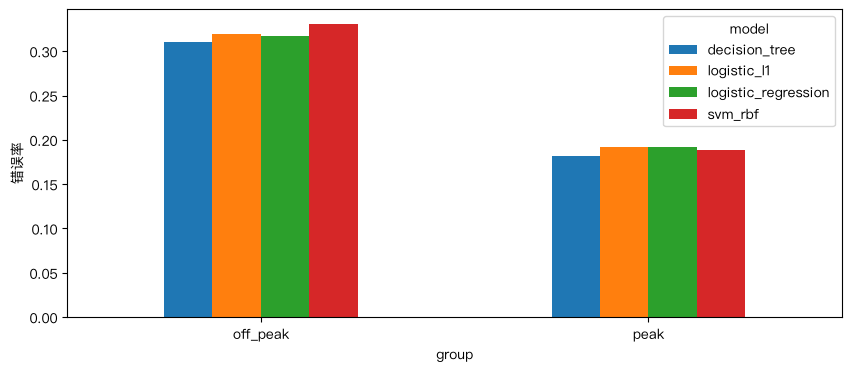

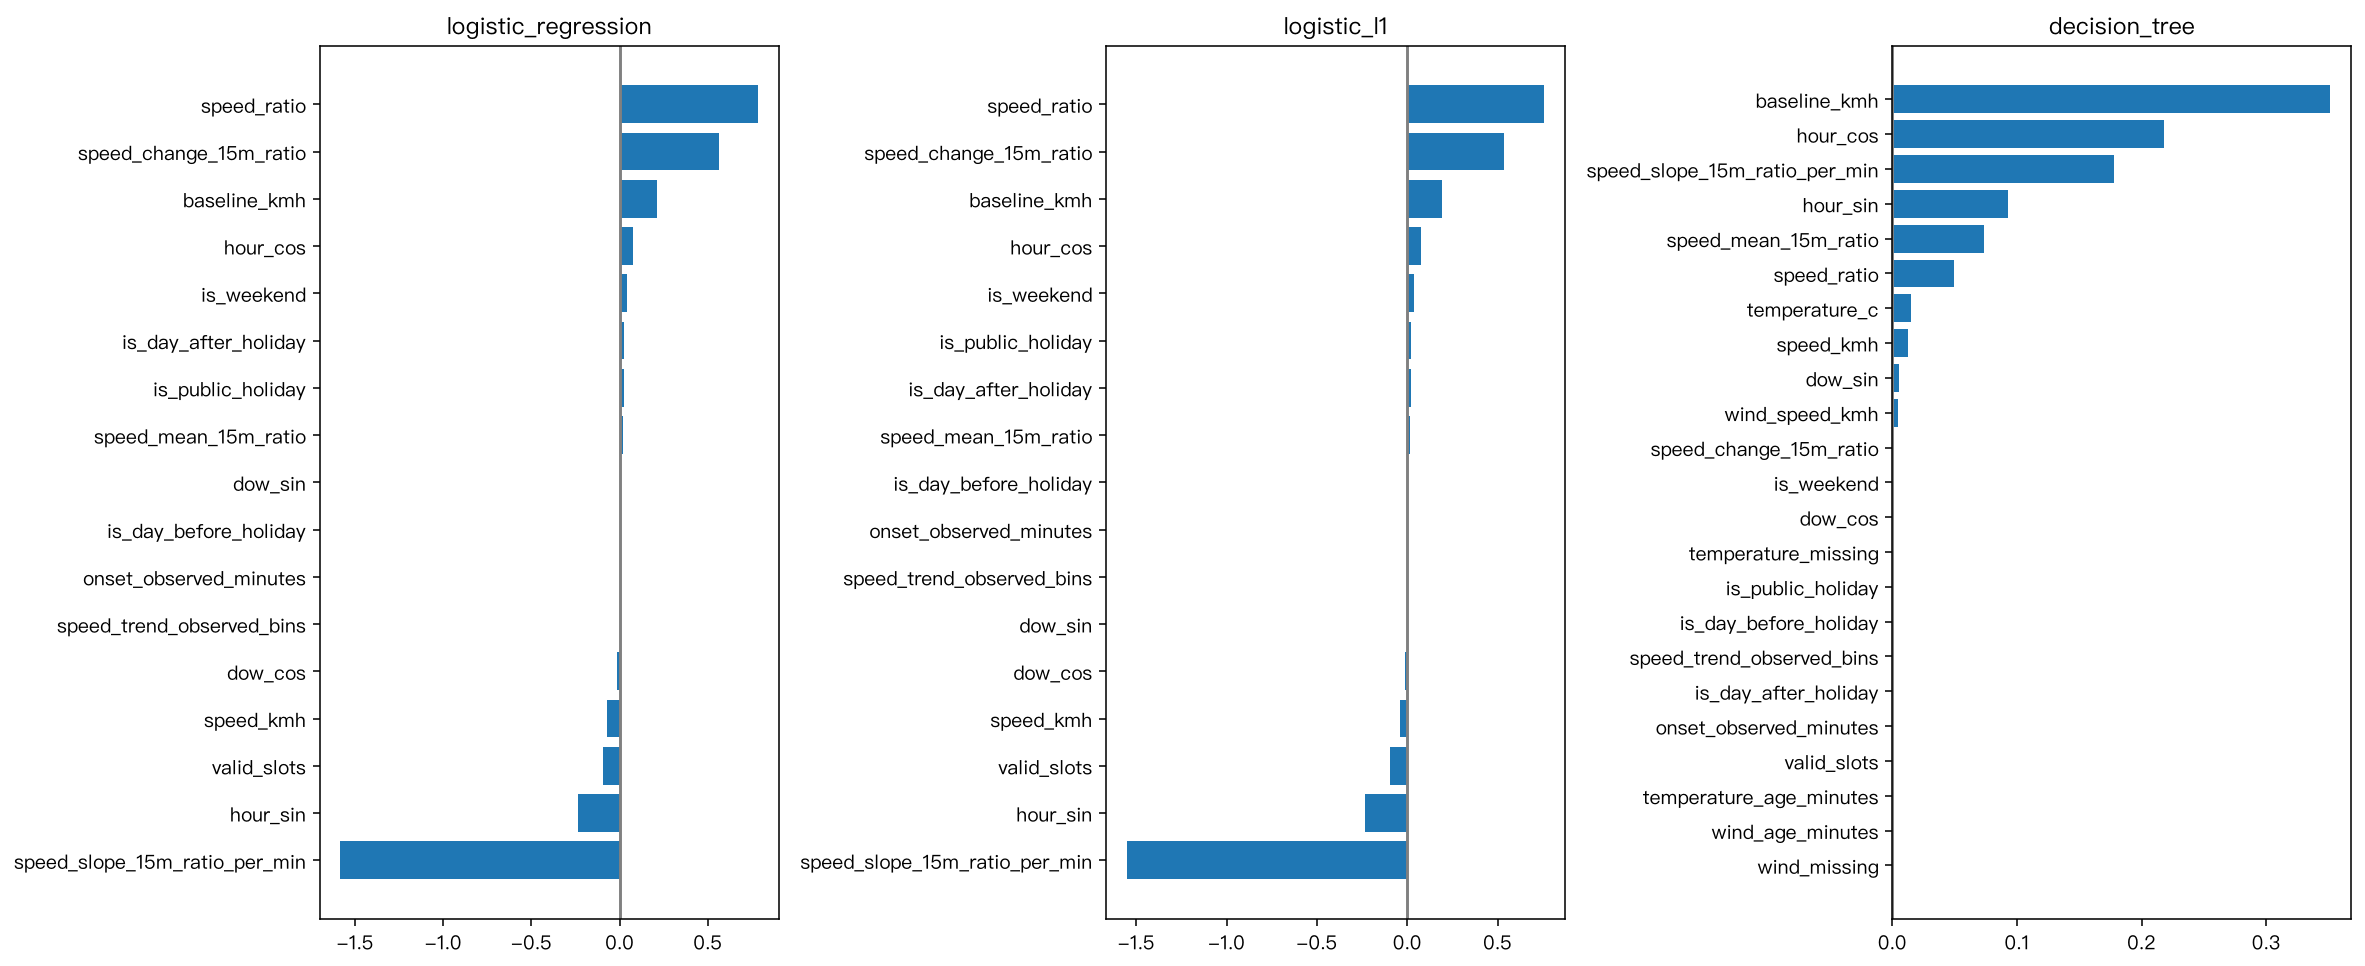

In [9]:
interpretation=pd.read_csv(M/'interpretation.csv')
for model in ['logistic_regression','logistic_l1','decision_tree']:
 fs=selected.loc[selected.model.eq(model),'feature_set'].iloc[0]
 values=interpretation.loc[interpretation.model.eq(model)&interpretation.feature_set.eq(fs)]
 display(values[['model','feature','value']])
display(pd.DataFrame(json.loads((M/'model_summaries.json').read_text())))
errors=pd.read_csv(M/'error_groups.csv').merge(selected[['model','feature_set']],on=['model','feature_set'],validate='many_to_one')
display(errors.loc[errors.dimension.eq('peak')]);display(errors.loc[errors.dimension.eq('detector_id')])
errors.loc[errors.dimension.eq('peak')].pivot(index='group',columns='model',values='error_rate').plot.bar(figsize=(10,4),rot=0);plt.ylabel('错误率');plt.show()
display(Image(filename=str(A/'figures/07_coefficients.png')))

**本段代码说明**

- **目的与输入：** 解释模型和错误集中位置。

- **处理方法与参数：** 显示含零的L1系数、树重要性、校准角色摘要；高峰固定07–10、17–20。

- **如何阅读结果：** 分组同时查看n；非零系数不是独立因果贡献。

- **检查与限制：** RBF SVM没有线性系数；检测器不等于道路，小样本组不能过度解释。

## 7. 最终核验和交接边界

In [10]:
final=verify_bundle();print(final)
print('实际历史本地概率重放：',json.loads((A/'original_local_verification.json').read_text())['max_pipeline_score_difference'])
print('公开审计默认不需要模型二进制；要重做概率重放，请完整重训并运行verify_workflow。')
print('组员旧24车道RF/HGB结果未混排；待96同队列预测交接。')

{'status': 'passed', 'prediction_rows': 557160, 'metric_rows': 600, 'arms': 20, 'arm_splits': 60, 'candidates': 224, 'sources': 94, 'release_alignment': 'not_rechecked_without_release', 'source_bytes_rechecked': False, 'probability_replay': 'historical local receipt; requires local fitted_pipelines.joblib to rerun', 'historical_git': {'commit': '36eafdabaafa5df450e1eaf40621392470203a08', 'dirty': True}, 'scientific_approval': 'pending_team_review'}
实际历史本地概率重放： 0.0
公开审计默认不需要模型二进制；要重做概率重放，请完整重训并运行verify_workflow。
组员旧24车道RF/HGB结果未混排；待96同队列预测交接。


**本段代码说明**

- **目的与输入：** 再次核验公开产物及来源/配置。

- **处理方法与参数：** 600指标、60个臂与split、224候选、557160预测及SHA对应。

- **如何阅读结果：** status通过是已执行检查的范围，不替代全组科学定义批准。

- **检查与限制：** 原始数据ZIP、个人缓存和模型二进制未提交；恢复定义、邻居、雨量/事故/活动的限制继续保留。